# 04 · Benchmarking
AUROC, AUPR, FPR@95%TPR for MFA(+EVT) and all baselines; operating points; latency; downstream hallucination.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)

In [2]:
m = pd.read_csv('results/ood_metrics.csv')
m[['method','All AUROC','Near AUROC','Adv AUROC','Far AUROC','All FPR@95TPR','Near FPR@95TPR','All AUPR_OOD']].round(3)

,method,All AUROC,Near AUROC,Adv AUROC,Far AUROC,All FPR@95TPR,Near FPR@95TPR,All AUPR_OOD
0,MFA min-Mahalanobis D²,0.767,0.736,0.559,0.988,0.539,0.698,0.928
1,MFA neg. log-likelihood,0.792,0.756,0.608,0.991,0.543,0.744,0.935
2,MFA + EVT (proposed),0.767,0.736,0.559,0.988,0.539,0.698,0.928
3,Cosine NN (FAISS),0.841,0.662,0.762,0.996,0.457,0.837,0.954
4,K-Means Euclidean,0.770,0.481,0.669,0.996,0.494,0.837,0.934
5,Diagonal GMM,0.769,0.507,0.656,0.994,0.494,0.814,0.932
6,Full-cov GMM,0.797,0.772,0.619,0.986,0.560,0.767,0.936
7,Single Gaussian (Ledoit-Wolf),0.882,0.760,0.819,0.999,0.346,0.674,0.966


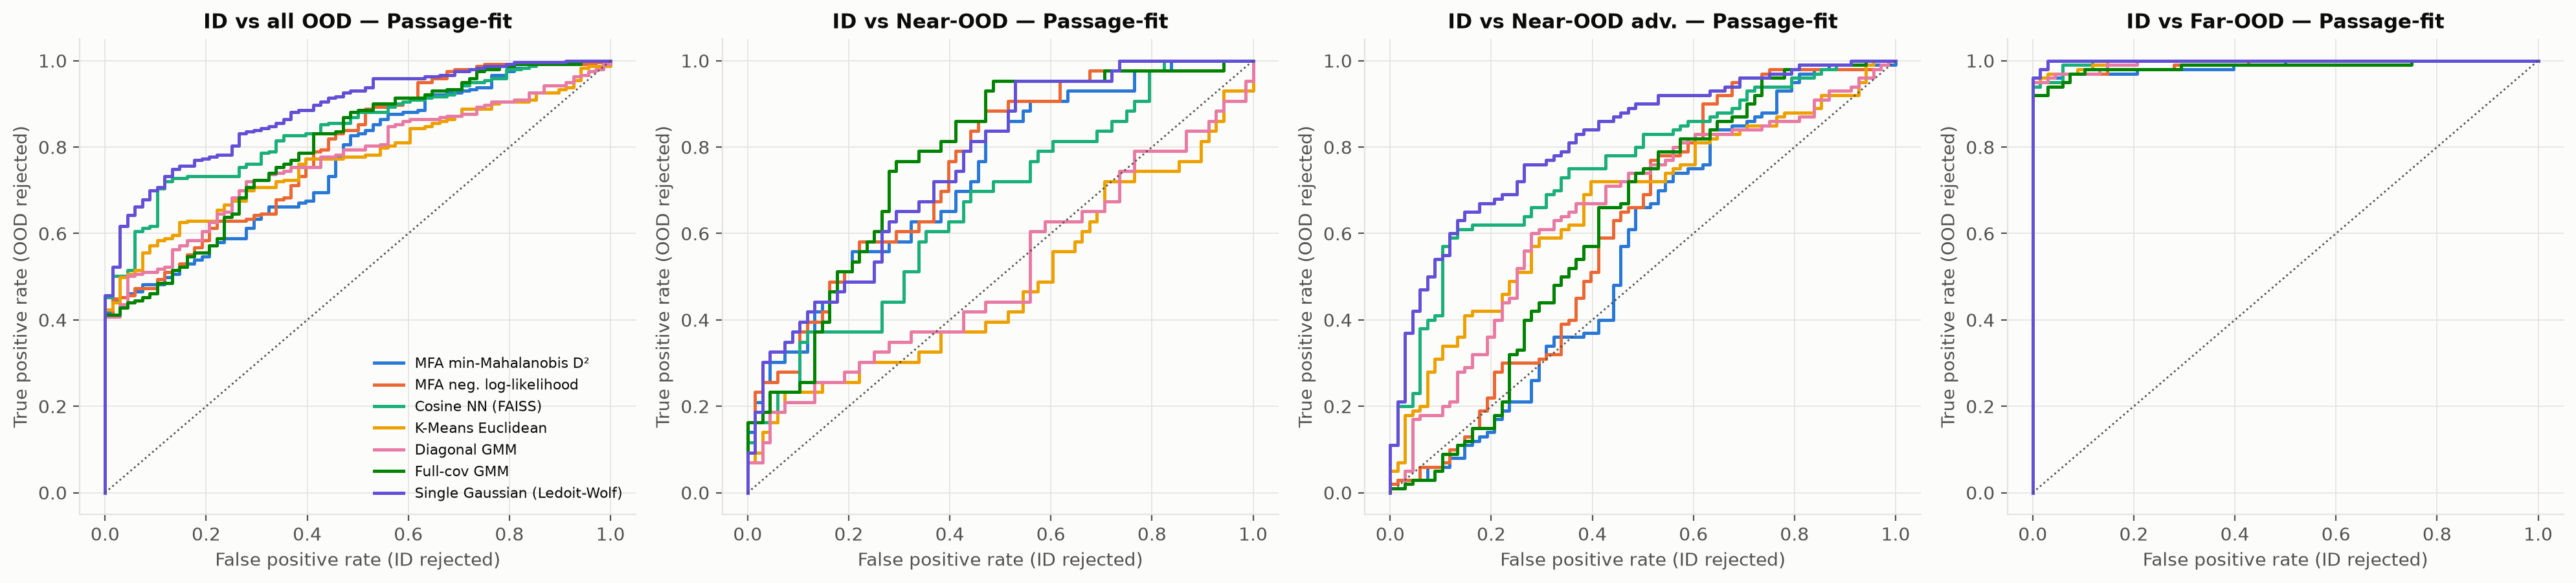

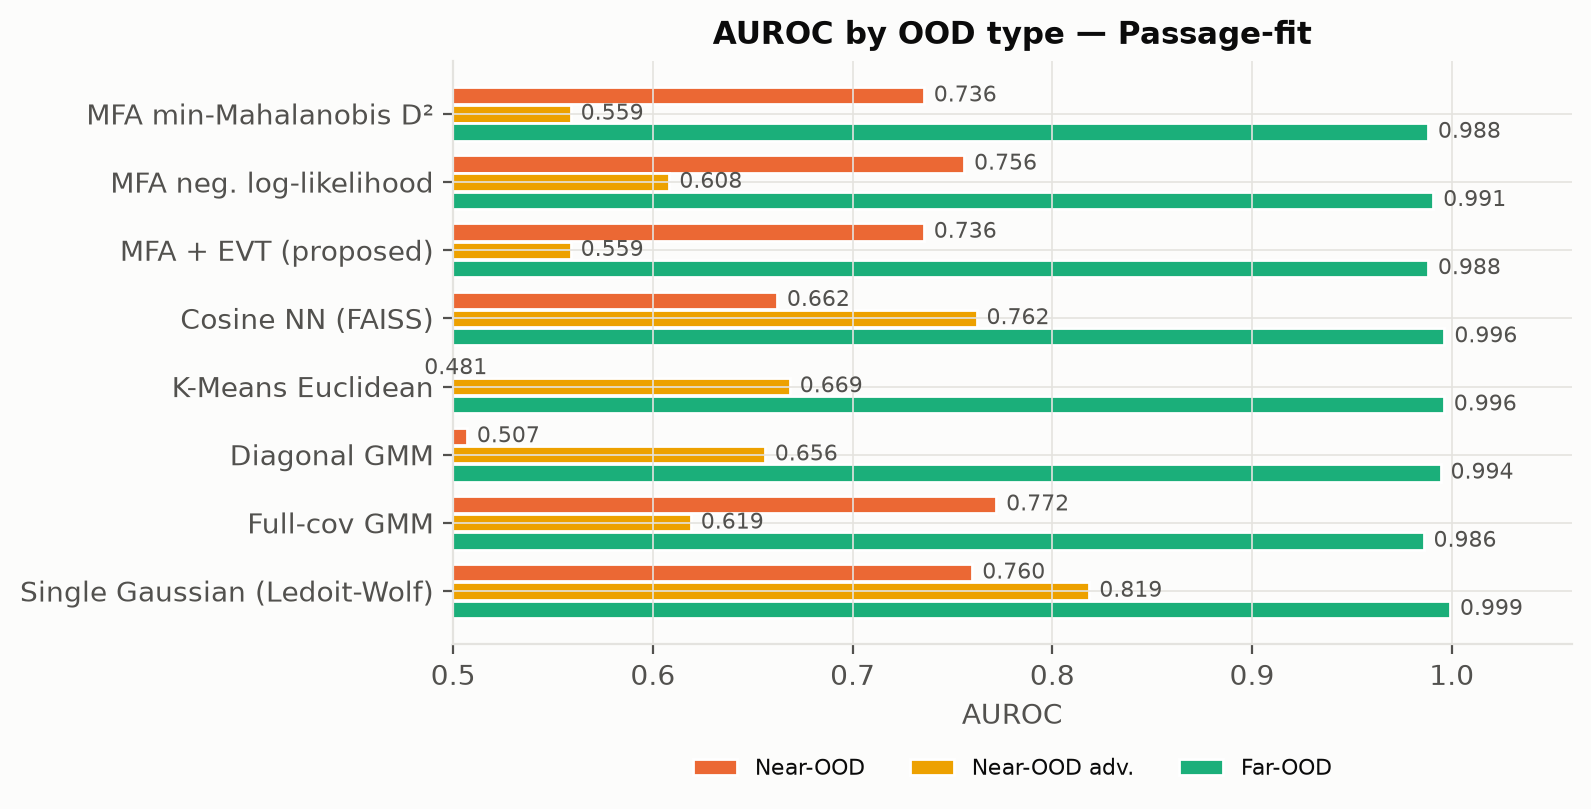

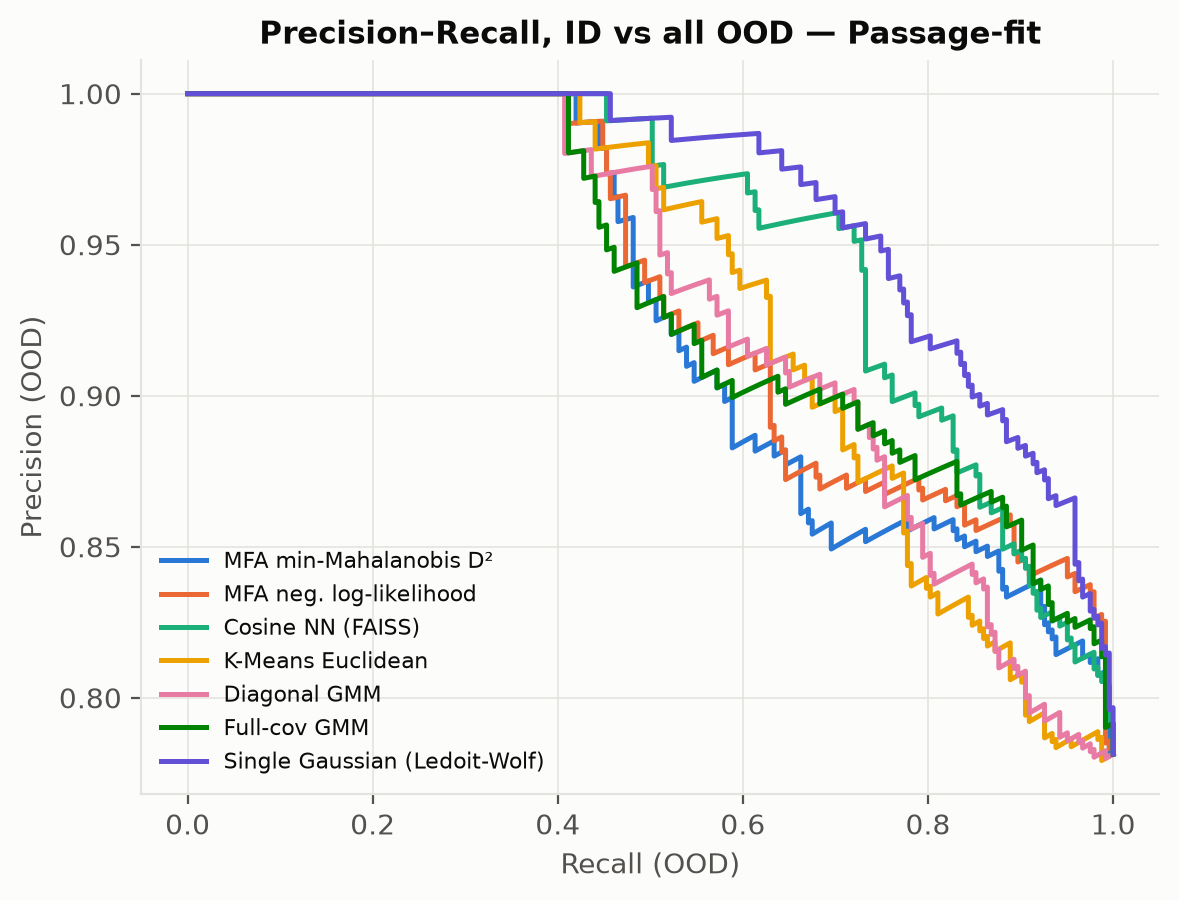

In [3]:
display(Image('results/roc_curve.png'))
display(Image('results/auroc_bars.png'))
display(Image('results/pr_curve.png'))

## Operating points (1 % validation false-alarm budget vs. EVT α)

In [4]:
pd.read_csv('results/operating_points.csv').round(3)

,source,method,rule,ID pass rate,Near-OOD reject rate,Near-OOD adv. reject rate,Far-OOD reject rate
0,passage,MFA min-Mahalanobis D²,val 99th pct,0.897,0.326,0.06,0.97
1,passage,MFA neg. log-likelihood,val 99th pct,0.853,0.395,0.13,0.97
2,passage,Cosine NN (FAISS),val 99th pct,0.721,0.442,0.64,1.00
3,passage,K-Means Euclidean,val 99th pct,1.000,0.070,0.05,0.95
4,passage,Diagonal GMM,val 99th pct,0.971,0.093,0.02,0.95
5,passage,Full-cov GMM,val 99th pct,0.765,0.581,0.29,0.98
6,passage,Single Gaussian (Ledoit-Wolf),val 99th pct,0.985,0.186,0.21,0.98
7,passage,MFA + EVT (proposed),S(q) < 0.5,0.706,0.581,0.27,0.98
8,passage,MFA + EVT (proposed),S(q) < 0.2,0.853,0.419,0.10,0.97
9,passage,MFA + EVT (proposed),S(q) < 0.1,0.926,0.326,0.05,0.97


## Latency

In [5]:
pd.read_csv('results/latency_report.csv').round(3)

,component,n,mean_ms,p50_ms,p95_ms,p99_ms
0,Woodbury MFA scoring (guardrail),1000,0.840,0.774,1.452,1.767
1,Dense precomputed precision,1000,1.195,1.012,2.087,2.404
2,Naive full inversion per query,50,2936.771,2913.377,3258.214,3769.550
3,"Query embedding (MiniLM, CPU)",200,9.019,7.719,15.407,21.381


## Downstream hallucination: unguarded vs guarded RAG

In [6]:
pd.read_csv('results/rag_comparison.csv').round(3)

,Prompt,Metric,Unguarded RAG,"Guarded (EVT, α=0.01)","Guarded (question-calibrated EVT, α=0.1)"
0,strict,"Faithfulness, ID (answered queries)",0.432,0.432,0.432
1,strict,ID answer rate,0.471,0.471,0.441
2,strict,ID queries wrongly blocked,0.000,0.000,0.074
3,strict,OOD queries blocked by guardrail,0.000,0.354,0.469
4,strict,"Hallucination rate, all OOD",0.115,0.095,0.074
5,strict,"Hallucination rate, Near-OOD",0.442,0.442,0.326
6,strict,"Hallucination rate, Near-OOD adv.",0.040,0.040,0.040
7,strict,"Hallucination rate, Far-OOD",0.050,0.000,0.000
8,strict,"Unsupported answers (NLI), all OOD",0.082,0.070,0.049
9,naive,OOD queries blocked by guardrail,0.000,0.354,0.469


Naive prompt (no abstention instruction): OOD queries that received a substantive answer without the guardrail, and whether each guarded variant blocks them.

In [7]:
r = pd.read_csv('results/rag_eval_per_query.csv')
pd.set_option('display.max_colwidth', 120)
n = r[(r.regime=='naive') & ~r.unguarded_abstain]
n[['label','query_text','unguarded_answer','guarded_blocked','guarded_qcal_blocked']].head(12)

,label,query_text,unguarded_answer,guarded_blocked,guarded_qcal_blocked
311,NEAR_OOD,You are an investment banker and your only resource(s) to answer the following question is (are): the statement of f...,Adobe's FY2015 operating cash flow ratio was 1. 26.,False,False
312,NEAR_OOD,What is Adobe's year-over-year change in unadjusted operating income from FY2015 to FY2016 (in units of percents and...,"Adobe's year-over-year change in unadjusted operating income from FY2015 to FY2016 was +2.0%, calculated as ((Operat...",False,True
314,NEAR_OOD,Does Adobe have an improving operating margin profile as of FY2022? If operating margin is not a useful metric for a...,"Yes, Adobe's operating margin improved from 2020 to 2021, increasing by $18 million or 1%. However, it declined slig...",False,True
316,NEAR_OOD,Answer the following question as if you are an equity research analyst and have lost internet connection so you do n...,"Based on the information provided, there's no direct D&A percentage margin mentioned for FY2015. The closest data gi...",False,False
318,NEAR_OOD,What are the major products and services that AMD sells as of FY22?,"AMD primarily sells processors, graphics processing units (GPUs), and related chips. They also offer software develo...",False,False
319,NEAR_OOD,What drove revenue change as of the FY22 for AMD?,"Product sales increased $4.9 billion, or 10%, mainly due to higher production volumes for the F-35 program and class...",False,False
320,NEAR_OOD,What drove operating margin change as of the FY22 for AMD? If operating margin is not a useful metric for a company ...,"The operating margin increased $30 million, or 16%, mainly due to higher electricity prices in Bulgaria and improved...",False,False
321,NEAR_OOD,"Among operations, investing, and financing activities, which brought in the most (or lost the least) cash flow for A...","In FY22, operating activities brought in the most cash flow with a total of $21.1 billion, while investing activitie...",False,False
322,NEAR_OOD,"From FY21 to FY22, excluding Embedded, in which AMD reporting segment did sales proportionally increase the most?","In the Segment & All Other category from FY21 to FY22, sales proportionally increased the most at Display Technologi...",False,False
324,NEAR_OOD,"Considering the data in the balance sheet, what is Block's (formerly known as Square) FY2016 working capital ratio? ...",Block's (formerly known as Square)'s FY2016 working capital ratio was 1.6:1.,False,True
